## Libraries

In [1]:
import torch
import torchvision
import matplotlib.pyplot as plt

from torchvision import transforms, datasets
from torch.utils.data import DataLoader 
from torch import nn, optim

import numpy as np      # numpy: library for working with grids of numbers (images are grids)
import cv2              # OpenCV: image processing (crop, resize, find shapes)
from PIL import Image   # Pillow: opens image files like PNG

import torch.nn.functional as F 

## Download MNIST 

In [2]:
transform = transforms.ToTensor()

train_data = datasets.MNIST(root='data', train=True, download=True, transform=transform)
test_data = datasets.MNIST(root='data', train=False, download=True, transform=transform)

print(f"Number of training samples: {len(train_data)}")
print(f"Number of test samples: {len(test_data)}")

Number of training samples: 60000
Number of test samples: 10000


In [3]:
image, label = train_data[0]

print(f"Image shape: {image.shape}")
print(f"Label: {label}")

Image shape: torch.Size([1, 28, 28])
Label: 5


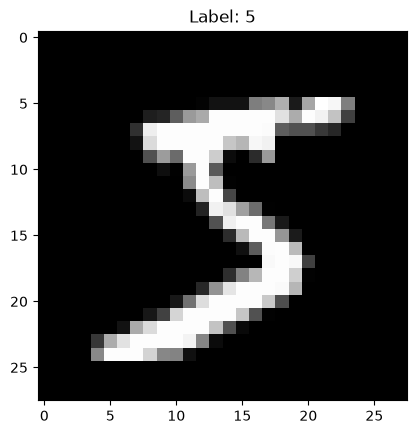

In [4]:
plt.imshow(image.squeeze(), cmap='gray')
plt.title(f"Label: {label}")
plt.show()

In [5]:
BATCH_SIZE = 64

train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False)

In [6]:
images, labels = next(iter(train_loader))

print(f"Batch image shape: {images.shape}")
print(f"Batch labels shape: {labels.shape}")
print("First 10 labels in the batch:", labels[:10].tolist())

Batch image shape: torch.Size([64, 1, 28, 28])
Batch labels shape: torch.Size([64])
First 10 labels in the batch: [3, 0, 4, 2, 0, 4, 4, 7, 4, 0]


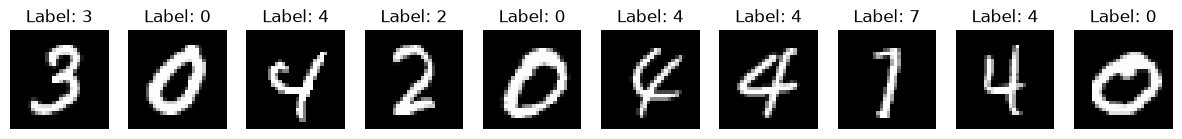

In [7]:
fig, axes = plt.subplots(1, 10, figsize=(15, 2))
for i in range(10):
    axes[i].imshow(images[i].squeeze(), cmap='gray')
    axes[i].set_title(f"Label: {labels[i].item()}")
    axes[i].axis('off')
plt.show()

## Build the Model

In [8]:
class DigitCNN(nn.Module):
    def __init__(self):
        super(DigitCNN, self).__init__()
        # ---------- Part 1: feature finder ----------
        self.features = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        # ---------- Part 2: decision maker ----------
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=64 * 7 * 7, out_features=128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(in_features=128, out_features=10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

model = DigitCNN().to(device)

print(model)

Using device: cpu
DigitCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [9]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

EPOCHS = 5

def evaluate(model, loader):
    model.eval()          # switch to "evaluation mode" (turns Dropout off, we want the full model)
    correct = 0           # counts the correct guesses
    total = 0             # counts all the images checked

    with torch.no_grad():                          
        for images, labels in loader:               
            images, labels = images.to(device), labels.to(device)
            scores = model(images)                 
            guesses = scores.argmax(dim=1)          
            correct += (guesses == labels).sum().item()   
            total += labels.size(0)                

    return 100 * correct / total                    

# ---------------- The training loop ----------------
for epoch in range(EPOCHS):                         # repeat for each epoch
    model.train()                                   # switch to "training mode" (Dropout on)
    running_loss = 0.0                              # adds up the loss over the epoch
    correct = 0                                     # correct guesses on training data
    total = 0                                       # images seen so far

    for images, labels in train_loader:             # go through the training data batch by batch
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()                       # clear the old adjustments from the last batch
        scores = model(images)                      # 1. Predict
        loss = criterion(scores, labels)            # 2. Measure how wrong it was
        loss.backward()                             # 3. Find which weights are to blame (backpropagation)
        optimizer.step()                            # 4. Adjust the weights a little

        # Keep statistics so we can print them (this part doesn't affect learning)
        running_loss += loss.item() * labels.size(0)
        correct += (scores.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    # End of the epoch: calculate and print the results (like Keras verbose=1)
    train_loss = running_loss / total               # average loss over the epoch
    train_acc = 100 * correct / total               # training accuracy
    test_acc = evaluate(model, test_loader)         # accuracy on images it has never trained on

    print(f"Epoch {epoch + 1}/{EPOCHS} | "
          f"Train loss: {train_loss:.4f} | "
          f"Train acc: {train_acc:.2f}% | "
          f"Test acc: {test_acc:.2f}%")

Epoch 1/5 | Train loss: 0.2185 | Train acc: 93.23% | Test acc: 98.53%
Epoch 2/5 | Train loss: 0.0660 | Train acc: 97.97% | Test acc: 98.50%
Epoch 3/5 | Train loss: 0.0511 | Train acc: 98.40% | Test acc: 99.03%
Epoch 4/5 | Train loss: 0.0406 | Train acc: 98.76% | Test acc: 99.06%
Epoch 5/5 | Train loss: 0.0323 | Train acc: 99.01% | Test acc: 99.01%


In [10]:
torch.save(model.state_dict(), "model.pt")
print("Model saved to model.pt")

Model saved to model.pt


In [11]:
# Create a fresh, untrained model with the same structure
loaded_model = DigitCNN().to(device)

# Load the saved weights into it (map_location makes it work on CPU or GPU)
loaded_model.load_state_dict(torch.load("model.pt", map_location=device))

# Switch to evaluation mode: turns Dropout off, which we always want when predicting
loaded_model.eval()

# Its accuracy should match your last Test acc (about 99.11%)
print(f"Loaded model test accuracy: {evaluate(loaded_model, test_loader):.2f}%")

Loaded model test accuracy: 99.01%


## App

In [12]:
def center_by_mass(img):
    """
    Shifts a 28x28 image so the 'balance point' of the ink sits in the middle
    of the image. This is how the original MNIST digits were centered.
    """
    # moments = statistics about the shape of the ink in the image
    m = cv2.moments(img)

    # m00 is the total amount of ink. If it's 0, the image is blank, so do nothing.
    if m["m00"] == 0:
        return img

    # Center of mass: the average x and y position of the ink pixels
    cx = m["m10"] / m["m00"]
    cy = m["m01"] / m["m00"]

    # How far we need to move the digit so its center of mass lands at (14, 14),
    # the middle of a 28x28 image
    shift_x = int(round(14 - cx))
    shift_y = int(round(14 - cy))

    # Build a "shift" matrix and apply it: the image slides by shift_x and shift_y pixels
    M = np.float32([[1, 0, shift_x], [0, 1, shift_y]])
    return cv2.warpAffine(img, M, (28, 28))

In [13]:
def preprocess_digit(gray):
    """
    Takes a grayscale image (2D numpy array, values 0-255) containing ONE digit.
    Returns a 28x28 image in MNIST format: white digit on black background, centered.
    """

    # 1. Make sure the digit is WHITE on a BLACK background (MNIST style).
    if gray.mean() > 127:
        gray = 255 - gray

    # 2. Separate ink from background with Otsu's automatic cutoff.
    _, bw = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    # 3. Find the coordinates of every ink pixel. If none, the image is blank.
    coords = cv2.findNonZero(bw)
    if coords is None:
        raise ValueError("No digit found in the image (it looks blank).")

    # 4. Crop tightly around the digit.
    x, y, w, h = cv2.boundingRect(coords)
    digit = bw[y:y + h, x:x + w]    # we now crop the clean black/white version (bw)

    # 4b. NEW: THICKEN the strokes. MNIST strokes are about 10% as thick as the digit is tall.
    #     kernel = the size of the "brush" that grows the ink outward.
    #     We make it ~10% of the digit's biggest side, and force it to be at least 3 pixels.
    k = max(3, int(max(w, h) * 0.10))
    kernel = np.ones((k, k), np.uint8)             # a k x k square of ones
    digit = cv2.dilate(digit, kernel, iterations=1)  # dilate = grow white areas outward

    # 5. Resize so the LONGEST side becomes 20 pixels, keeping proportions.
    scale = 20 / max(w, h)
    new_w = max(1, int(round(w * scale)))
    new_h = max(1, int(round(h * scale)))
    digit = cv2.resize(digit, (new_w, new_h), interpolation=cv2.INTER_AREA)

    # 6. Paste the digit into the middle of an empty black 28x28 canvas.
    canvas = np.zeros((28, 28), dtype=np.uint8)
    x_off = (28 - new_w) // 2
    y_off = (28 - new_h) // 2
    canvas[y_off:y_off + new_h, x_off:x_off + new_w] = digit

    return center_by_mass(canvas)   # shift the digit so its ink balances in the middle, like MNIST

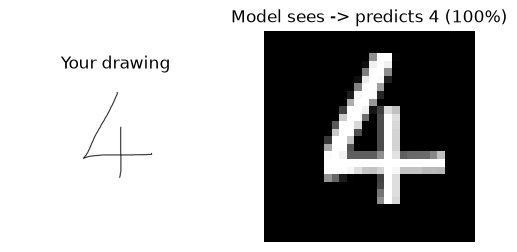

In [14]:
def predict_from_file(path):
    # Open the image file and convert it to grayscale ("L" = one channel of brightness)
    gray = np.array(Image.open(path).convert("L"))

    # Convert the drawing into MNIST format using our function
    processed = preprocess_digit(gray)

    # Turn it into what the model expects:
    #   /255.0 -> pixel values from 0-255 become 0-1 (same as ToTensor did in training)
    #   [None, None] -> adds two dimensions so the shape becomes [1, 1, 28, 28]
    #                   (1 image, 1 color channel, 28x28 pixels)
    tensor = torch.tensor(processed / 255.0, dtype=torch.float32)[None, None].to(device)

    # Ask the model (no_grad = not training, just predicting)
    with torch.no_grad():
        scores = loaded_model(tensor)
        probs = F.softmax(scores, dim=1)[0]        # softmax: scores -> percentages that add up to 1

    guess = probs.argmax().item()                  # the digit with the highest probability
    confidence = probs[guess].item() * 100

    # Show the original drawing next to what the model actually saw
    fig, axes = plt.subplots(1, 2, figsize=(6, 3))
    axes[0].imshow(gray, cmap="gray")
    axes[0].set_title("Your drawing")
    axes[1].imshow(processed, cmap="gray")
    axes[1].set_title(f"Model sees -> predicts {guess} ({confidence:.0f}%)")
    for a in axes:
        a.axis("off")
    plt.show()


# Try it on your first drawing (change the file name for the others)
predict_from_file("digit1.png")

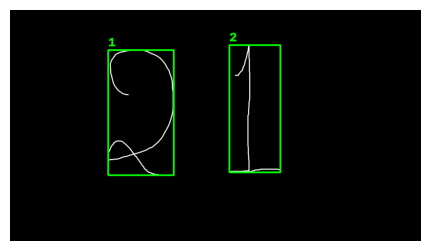

Digits found: 2


In [15]:
def find_digit_boxes(gray):
    """
    Takes a grayscale image of a whole number (several digits).
    Returns:
      - boxes: a list of (x, y, w, h) rectangles, one per digit, sorted left to right
      - gray:  the image, flipped if needed so ink is WHITE on a BLACK background
    """

    # 1. Make sure ink is white on black (same rule as before: a bright average means a white background, so we flip it)
    if gray.mean() > 127:
        gray = 255 - gray

    # 2. Turn the picture into pure black/white: ink = 255, background = 0
    _, bw = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    # 3. Find contours = the outlines of every separate blob of ink. RETR_EXTERNAL means "only the outer outline of each blob" (so the hole inside a 0 or an 8 doesn't count as another shape).
    contours, _ = cv2.findContours(bw, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    # 4. For each blob, get its bounding box: the smallest rectangle around it
    boxes = [cv2.boundingRect(c) for c in contours]

    if len(boxes) == 0:
        return [], gray    # nothing was drawn

    # 5. Remove tiny specks (dust, stray dots): keep only boxes whose height is at least 30% of the tallest box.
    tallest = max(h for (x, y, w, h) in boxes)
    boxes = [b for b in boxes if b[3] > 0.3 * tallest]

    # 6. Sort the boxes by their x position (the first number in each box), so the digits are in reading order: left to right.
    boxes.sort(key=lambda b: b[0])

    return boxes, gray


def show_boxes(path):
    # Open the image and convert it to grayscale
    gray = np.array(Image.open(path).convert("L"))

    # Find the digit boxes
    boxes, oriented = find_digit_boxes(gray)

    # Convert to a 3-channel (color) image so we can draw colored rectangles on it
    vis = cv2.cvtColor(oriented, cv2.COLOR_GRAY2BGR)

    # Draw a green rectangle around each digit, with its position number (1, 2, 3...)
    for i, (x, y, w, h) in enumerate(boxes, start=1):
        cv2.rectangle(vis, (x, y), (x + w, y + h), (0, 255, 0), 3)
        cv2.putText(vis, str(i), (x, max(y - 10, 20)),
                    cv2.FONT_HERSHEY_SIMPLEX, 1.2, (0, 255, 0), 3)

    # Show the result (vis[:, :, ::-1] converts OpenCV's color order to matplotlib's)
    plt.figure(figsize=(8, 3))
    plt.imshow(vis[:, :, ::-1])
    plt.axis("off")
    plt.show()

    print("Digits found:", len(boxes))


show_boxes("number1.png")

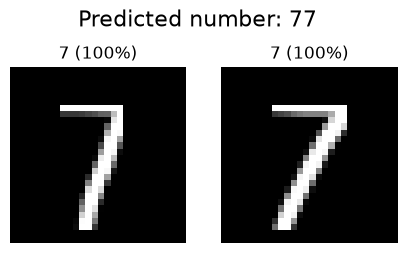

Number: 77


In [16]:
def predict_number(path, show=True):
    """
    Reads a whole handwritten number from an image file.
    Returns the number as a string (e.g. "700") and a list of confidences.
    """

    # Open the image and convert it to grayscale
    gray = np.array(Image.open(path).convert("L"))

    # Find the digit boxes (sorted left to right) and get the version of the image where ink is white on black
    boxes, oriented = find_digit_boxes(gray)

    if len(boxes) == 0:
        return "", []

    digits = []          # will hold the predicted digit for each box
    confidences = []     # will hold how sure the model was for each box
    processed_images = []  # the 28x28 pictures, so we can display them later

    for (x, y, w, h) in boxes:

        # Cut out this digit, with a little extra margin (pad) around it.
        # max(0, ...) stops us from going outside the image edges.
        pad = 10
        crop = oriented[max(0, y - pad): y + h + pad,
                        max(0, x - pad): x + w + pad]

        # Convert the crop into the 28x28 MNIST format (our function from Phase 2)
        processed = preprocess_digit(crop)
        processed_images.append(processed)

        # Turn it into the shape the model expects: [1, 1, 28, 28]
        tensor = torch.tensor(processed / 255.0, dtype=torch.float32)[None, None].to(device)

        # Ask the model and convert the 10 scores into percentages
        with torch.no_grad():
            probs = F.softmax(loaded_model(tensor), dim=1)[0]

        guess = probs.argmax().item()                 # the most likely digit
        digits.append(str(guess))                     # keep it as text so we can join them
        confidences.append(probs[guess].item() * 100)

    # Join the digits into one string: ["7", "0", "0"] -> "700"
    number = "".join(digits)

    # Show what the model saw for each digit, with its prediction above
    if show:
        fig, axes = plt.subplots(1, len(processed_images), figsize=(2.5 * len(processed_images), 3))
        axes = np.atleast_1d(axes)   # makes sure axes is a list even when there is only 1 digit
        for ax, img, d, c in zip(axes, processed_images, digits, confidences):
            ax.imshow(img, cmap="gray")
            ax.set_title(f"{d} ({c:.0f}%)")
            ax.axis("off")
        plt.suptitle(f"Predicted number: {number}", fontsize=16)
        plt.show()

    return number, confidences


number, confs = predict_number("number3.png")
print("Number:", number)

In [17]:
from utils import load_model, read_number

test_model = load_model("model.onnx")      
gray = np.array(Image.open("number3.png").convert("L"))
print(read_number(gray, test_model))

{'number': '77', 'digits': [{'digit': 7, 'confidence': 100.0, 'box': [362, 128, 176, 346]}, {'digit': 7, 'confidence': 100.0, 'box': [683, 179, 212, 345]}]}


In [18]:
# Export the trained model to ONNX: a file with the structure AND weights that
# can run without PyTorch, using the much lighter onnxruntime library.
loaded_model.eval()                                  # evaluation mode (Dropout off)
dummy = torch.zeros(1, 1, 28, 28).to(device)         # a blank fake image, so the export knows the input shape

torch.onnx.export(
    loaded_model,                                    # the model to export
    dummy,                                           # example input
    "model.onnx",                                    # output file name
    input_names=["image"],                           # name of the input
    output_names=["scores"],                         # name of the output (10 scores)
    dynamic_axes={"image": {0: "batch"}},            # allow any number of images at once
    opset_version=17,
    dynamo=False,                                    # classic exporter, needs fewer extra packages
)
print("Saved model.onnx")

C:\Users\Dell\AppData\Local\Temp\ipykernel_1456\1265949699.py:6: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


Saved model.onnx


In [19]:
import onnxruntime as ort

session = ort.InferenceSession("model.onnx")         # load the ONNX model
images, labels = next(iter(test_loader))             # one batch of test images

with torch.no_grad():                                # scores from the PyTorch model
    torch_scores = loaded_model(images.to(device)).cpu().numpy()

onnx_scores = session.run(None, {"image": images.numpy()})[0]   # scores from the ONNX model

print("Max difference:", np.abs(torch_scores - onnx_scores).max())
print("Same guesses:", (torch_scores.argmax(1) == onnx_scores.argmax(1)).all())

Max difference: 3.8146973e-06
Same guesses: True
